# House Prices: preprocessing

This notebook does all the EDA and data preprocessing.



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from pathlib import Path

figures_dir = Path("results/figures")
# later when running from notebooks/: Path("../results/figures")
figures_dir.mkdir(parents=True, exist_ok=True)


# pink palette used for every plot<3
PINK = '#E8A0BF'
DARK_PINK = '#B85C85'
DEEP_PINK = '#8B1A5A'   # used to highlight flagged points

## 1. Load the data

Both files are read as they are. `test_ids` is saved now because `Id` gets dropped from the features later, and we need it for the submission file.

In [ ]:
train_raw = pd.read_csv('train.csv') #later on change path to '../data/raw/train.csv'
test_raw = pd.read_csv('test.csv')  # '../data/raw/test.csv'
test_ids = test_raw['Id']          # keep for the submission file

## 2. Outlier detection

Our numerical features are skewed (see the distributions in section 3), so instead of a z-score we use an **IQR test**. A value is flagged if it lies more than 3 x IQR below Q1 or above Q3. The usual 1.5 was overkill and flagged too many normal houses, so we use 3.

Only continuous columns are tested, and the thresholds are computed on train only. A flagged row is a candidate, not an automatic deletion.

In [ ]:
cont_cols = ['LotArea', 'LotFrontage', 'GrLivArea', 'TotalBsmtSF',
             '1stFlrSF', 'GarageArea', 'MasVnrArea']

q1 = train_raw[cont_cols].quantile(0.25)
q3 = train_raw[cont_cols].quantile(0.75)
iqr = q3 - q1

lower = q1 - 3 * iqr # 1.5 was kinda overkill
upper = q3 + 3 * iqr
flagged = (train_raw[cont_cols] < lower) | (train_raw[cont_cols] > upper)

print(flagged.sum())                                     # how many per column
print(train_raw.loc[flagged.any(axis=1), cont_cols + ['SalePrice']])

LotArea        34
LotFrontage    12
GrLivArea       4
TotalBsmtSF     5
1stFlrSF        3
GarageArea      3
MasVnrArea     25
dtype: int64
      LotArea  LotFrontage  GrLivArea  TotalBsmtSF  1stFlrSF  GarageArea  \
53      50271         68.0       1842         1842      1842         894   
58      13682         66.0       2945         1410      1426         641   
70      13651         95.0       2223         2223      2223         516   
105      9375         75.0       1992         1053      1053         648   
115      3230         34.0       1458          729       729         440   
...       ...          ...        ...          ...       ...         ...   
1373    11400          NaN       2633         2633      2633         804   
1383    25339          NaN       1416          816      1416         576   
1396    57200          NaN       1687          747      1687         572   
1417    16545          NaN       2450         1284      1310        1069   
1446    26142          Na

Flagged houses (deep pink) against normal houses (light pink). A flagged point that follows the trend, like a big house with a high price, is fine. One that sits far off the trend is a candidate for removal.

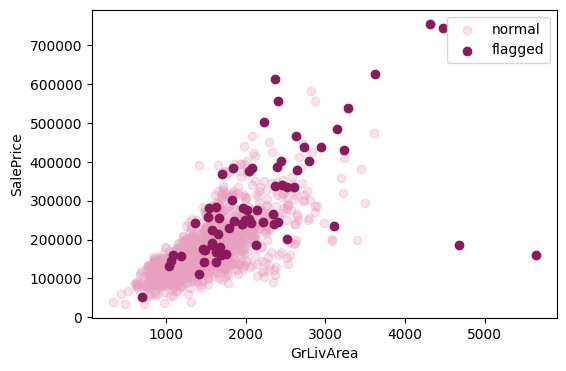

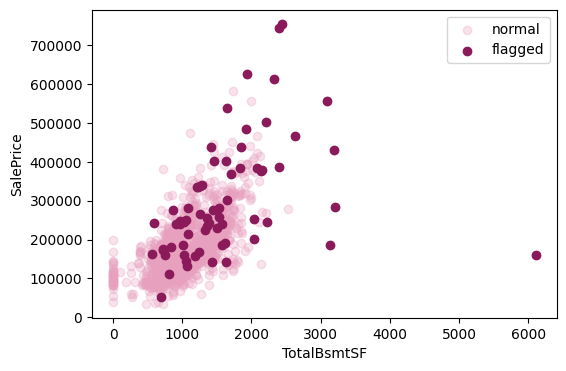

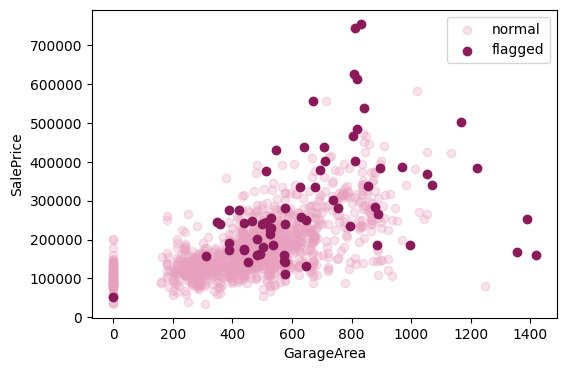

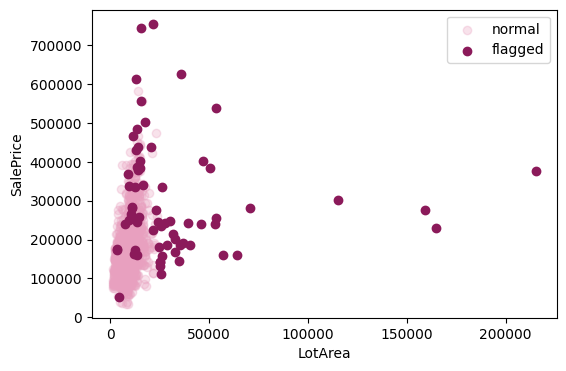

In [ ]:
out_rows = flagged.any(axis=1)

for col in ['GrLivArea', 'TotalBsmtSF', 'GarageArea', 'LotArea']:
    plt.figure(figsize=(6, 4))
    plt.scatter(train_raw[col], train_raw['SalePrice'], alpha=0.3, color=PINK, label='normal')
    plt.scatter(train_raw.loc[out_rows, col], train_raw.loc[out_rows, 'SalePrice'],
                color=DEEP_PINK, label='flagged')
    plt.xlabel(col); plt.ylabel('SalePrice'); plt.legend();
    plt.savefig(
    figures_dir / "scatterplots.png",
    dpi=300,
    bbox_inches="tight",
    )
    plt.show()

How many columns flag each row. A row flagged in several columns at once is more likely to be truly unusual than one flagged in a single column, which is often just a big lot.

In [ ]:
print(flagged.sum(axis=1)[out_rows].sort_values(ascending=False))

1298    7
523     5
197     2
496     2
1190    2
       ..
1373    1
1383    1
1396    1
1417    1
1446    1
Length: 68, dtype: int64


A closer look at Ids 524 and 1299 (deep pink): very large houses that sold for little. The trend line is fitted **without** them, so you can see how far below the prediction they sit.

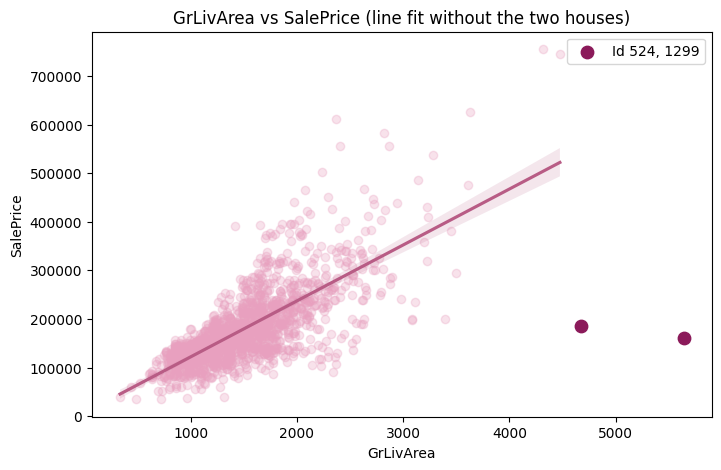

In [ ]:
sus = train_raw['Id'].isin([524, 1299])

plt.figure(figsize=(8, 5))
sns.regplot(data=train_raw[~sus], x='GrLivArea', y='SalePrice', color=PINK,
            scatter_kws={'alpha': 0.3}, line_kws={'color': DARK_PINK})
plt.scatter(train_raw.loc[sus, 'GrLivArea'], train_raw.loc[sus, 'SalePrice'],
            color=DEEP_PINK, s=80, label='Id 524, 1299')
plt.legend()
plt.title('GrLivArea vs SalePrice (line fit without the two houses)')
plt.savefig(
    figures_dir / "trend.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

The same houses as price per square foot. They sell for roughly a quarter to a third of the usual price per sqft, which suggests the recorded price doesn't reflect the whole house. Both are `Partial` sales (sold before the house was finished).

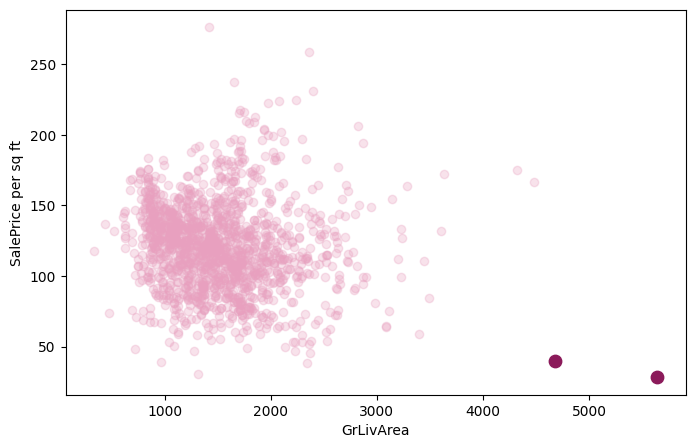

In [ ]:
ppsf = train_raw['SalePrice'] / train_raw['GrLivArea']
plt.figure(figsize=(8, 5))
plt.scatter(train_raw['GrLivArea'], ppsf, alpha=0.3, color=PINK)
plt.scatter(train_raw.loc[sus, 'GrLivArea'], ppsf[sus], color=DEEP_PINK, s=80)
plt.xlabel('GrLivArea'); plt.ylabel('SalePrice per sq ft')
plt.savefig(
    figures_dir / "outliers1.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### Outlier removal

We use this rule: drop houses with `GrLivArea > 4000` **and** `SalePrice < 300000`. That removes exactly Ids 524 and 1299.

The removal sits here, before cleaning, so these rows can't influence the medians and modes learned later. `test_raw` is never touched.

In [ ]:
#outlier removal
mask = (train_raw['GrLivArea'] > 4000) & (train_raw['SalePrice'] < 300000)
print(train_raw.loc[mask, ['Id', 'GrLivArea', 'SalePrice', 'SaleCondition']])   # Id 524 and 1299

train_raw = train_raw[~mask].reset_index(drop=True)
print(train_raw.shape)                                                          # expected 1458 rows

        Id  GrLivArea  SalePrice SaleCondition
523    524       4676     184750       Partial
1298  1299       5642     160000       Partial
(1458, 81)


## 3. Exploring the data

Start with the basics: the first rows, shape, dtypes and summary statistics.

In [ ]:
print(train_raw.head())
print(train_raw.shape)
print(train_raw.dtypes)
print(train_raw.describe())

   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  SalePrice  
0   2008        WD   

Missing values per column. Because pandas reads the text `NA` as NaN, many of these are not truly missing. For example, `NA` in `PoolQC` just means "no pool". Section 4 deals with that.

In [ ]:
train_raw.isna().sum()

,0
Id,0
MSSubClass,0
MSZoning,0
LotFrontage,259
LotArea,0
...,...
MoSold,0
YrSold,0
SaleType,0
SaleCondition,0


Non-null counts and dtypes per column.

In [ ]:
train_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1458 entries, 0 to 1457
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1458 non-null   int64  
 1   MSSubClass     1458 non-null   int64  
 2   MSZoning       1458 non-null   object 
 3   LotFrontage    1199 non-null   float64
 4   LotArea        1458 non-null   int64  
 5   Street         1458 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1458 non-null   object 
 8   LandContour    1458 non-null   object 
 9   Utilities      1458 non-null   object 
 10  LotConfig      1458 non-null   object 
 11  LandSlope      1458 non-null   object 
 12  Neighborhood   1458 non-null   object 
 13  Condition1     1458 non-null   object 
 14  Condition2     1458 non-null   object 
 15  BldgType       1458 non-null   object 
 16  HouseStyle     1458 non-null   object 
 17  OverallQual    1458 non-null   int64  
 18  OverallC

### Target variable

`SalePrice` is right-skewed. Its log is much closer to a normal distribution, which is why `y` is log-transformed at the end.

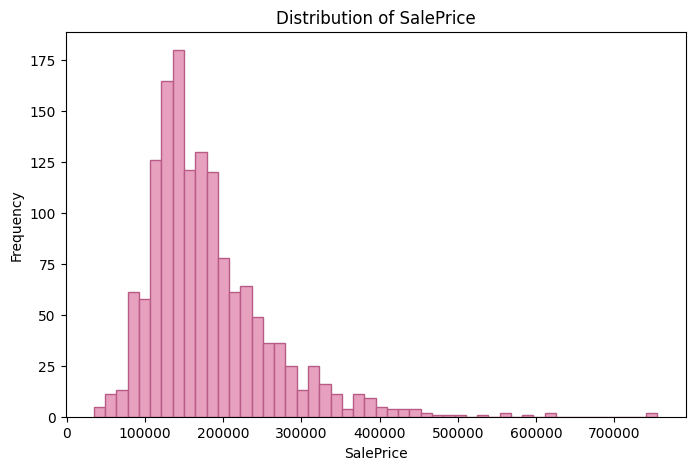

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(train_raw['SalePrice'], bins=50, color=PINK, edgecolor=DARK_PINK)
plt.xlabel('SalePrice')
plt.ylabel('Frequency')
plt.title('Distribution of SalePrice')
plt.savefig(
    figures_dir / "saleprice.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

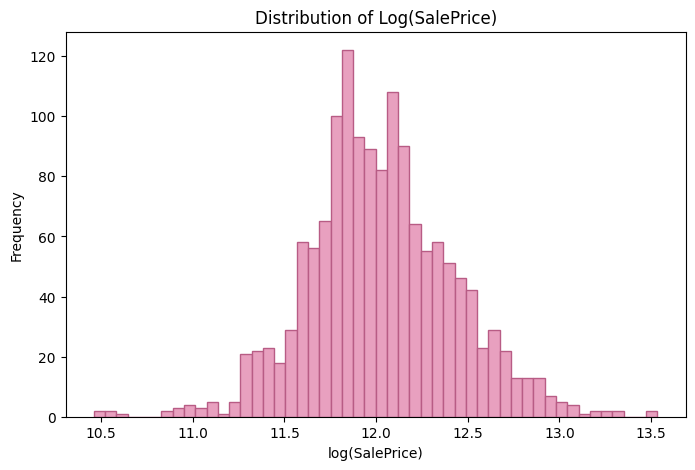

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(np.log(train_raw['SalePrice']), bins=50,
         color=PINK, edgecolor=DARK_PINK)

plt.xlabel('log(SalePrice)')
plt.ylabel('Frequency')
plt.title('Distribution of Log(SalePrice)')
plt.savefig(
    figures_dir / "saleprice_log.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### Numerical and categorical features

We look at the features that probably matter most (my own guess). First the distributions of the numerical ones, most of which are skewed.

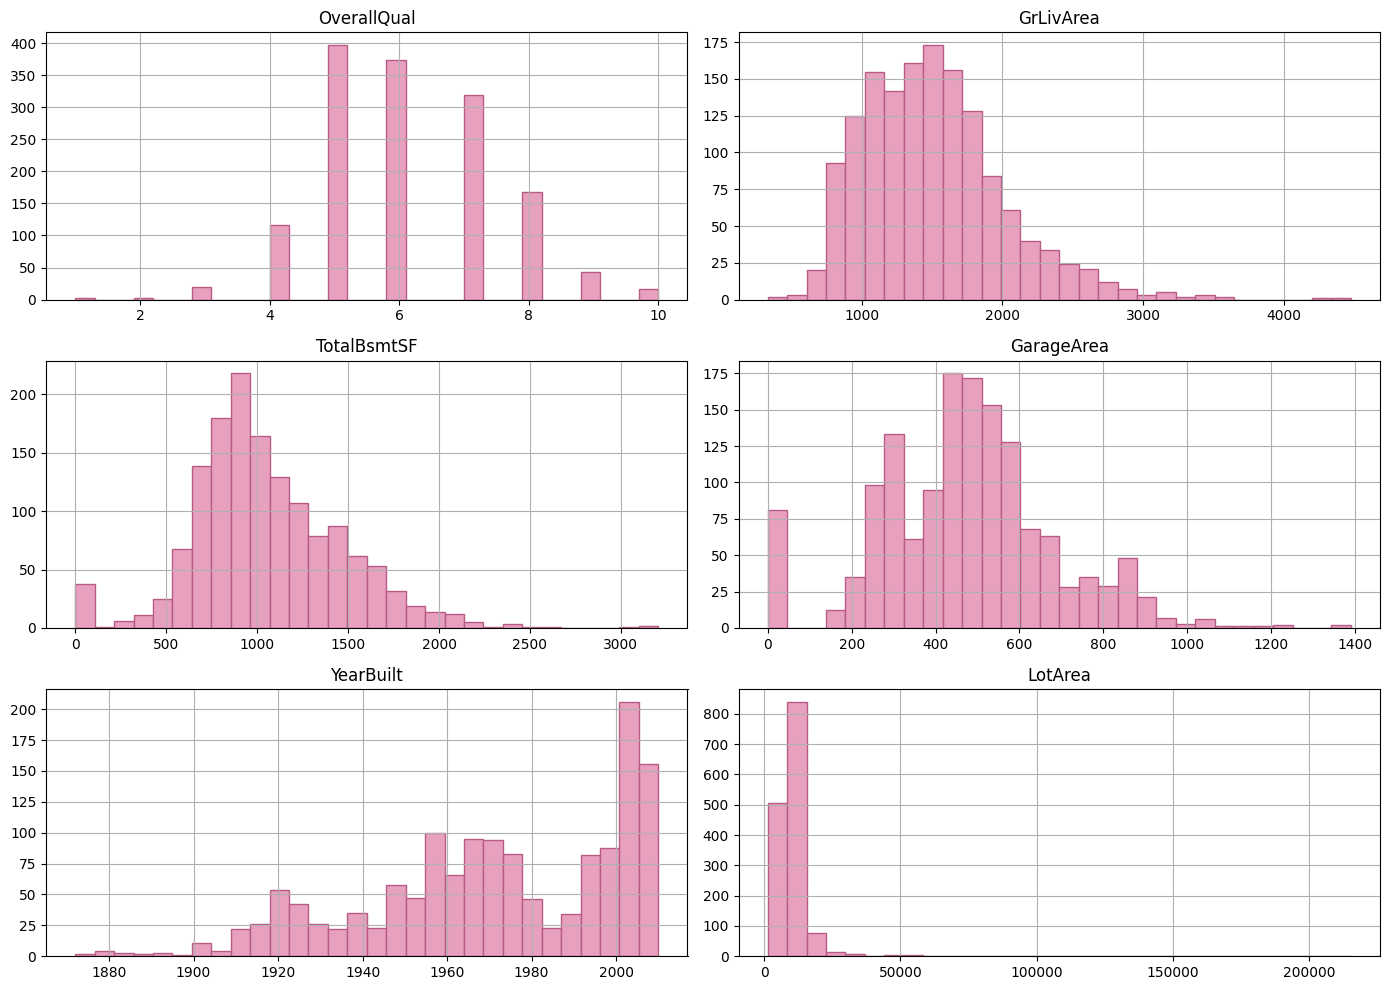

In [ ]:
# numerical features that are probably the most relevant

selected_numeric = [
    'OverallQual', 'GrLivArea', 'TotalBsmtSF',
    'GarageArea', 'YearBuilt', 'LotArea'
]

train_raw[selected_numeric].hist(figsize=(14, 10), bins=30, color=PINK, edgecolor=DARK_PINK)
plt.tight_layout()
plt.savefig(
    figures_dir / "histograms1.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

Value counts of the categorical features that also probably matter most. This shows which categories are common and which are rare.

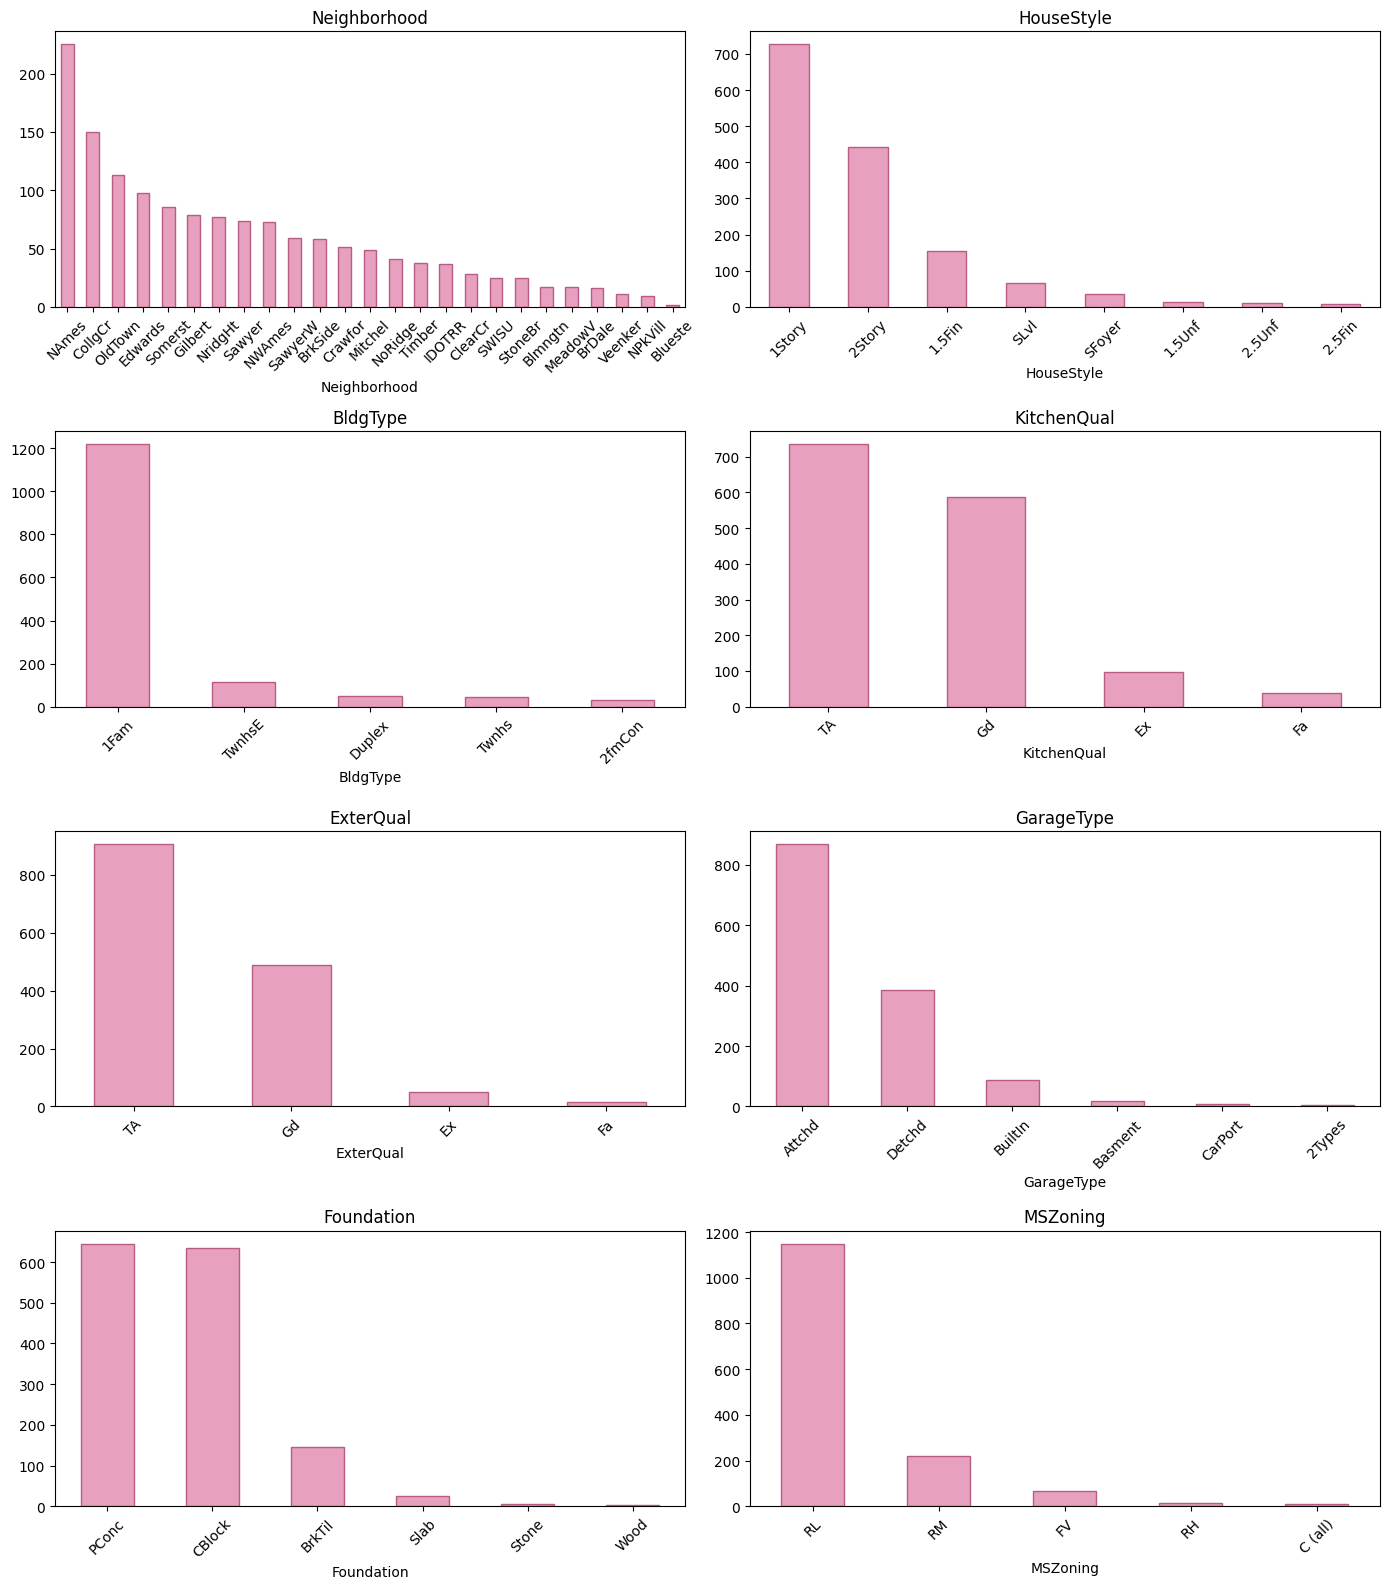

In [ ]:
#categorical features that also probably matter most imo

selected_categorical = [
    'Neighborhood', 'HouseStyle', 'BldgType',
    'KitchenQual', 'ExterQual', 'GarageType', 'Foundation', 'MSZoning'
]

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for i, col in enumerate(selected_categorical):
    train_raw[col].value_counts().plot(kind='bar', ax=axes[i], color=PINK, edgecolor=DARK_PINK)
    axes[i].set_title(col)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(
    figures_dir / "histograms2.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### Relationship with SalePrice

Scatter plots of each selected numerical feature against `SalePrice`.

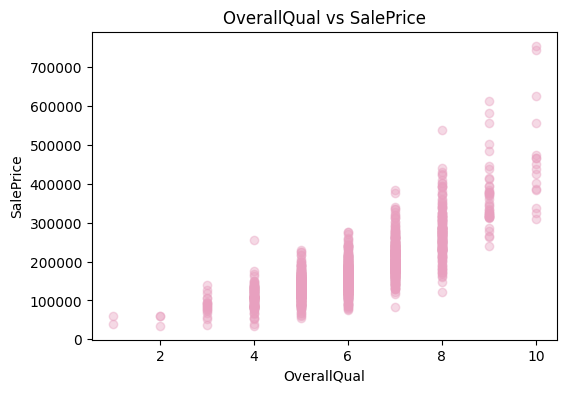

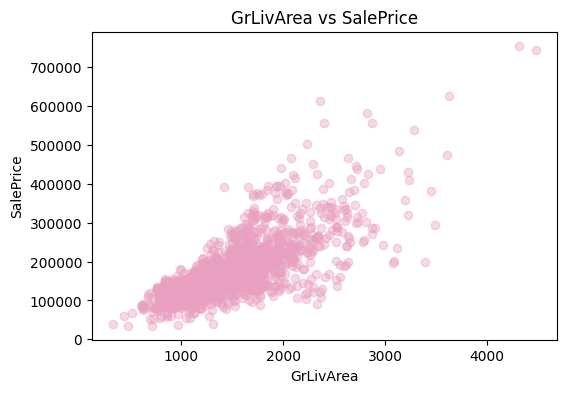

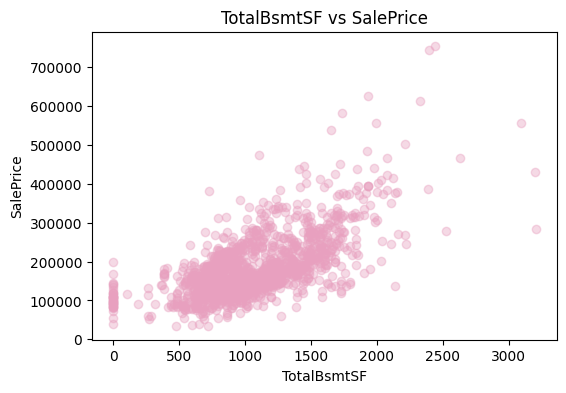

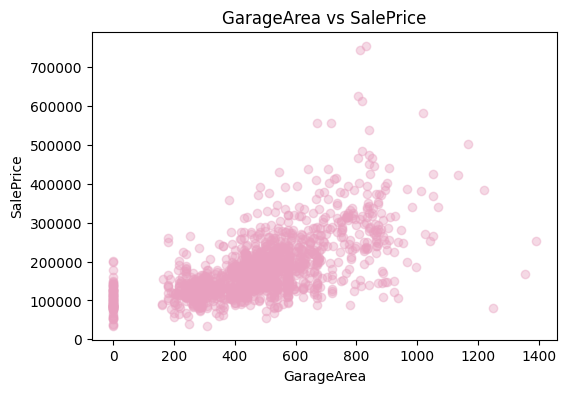

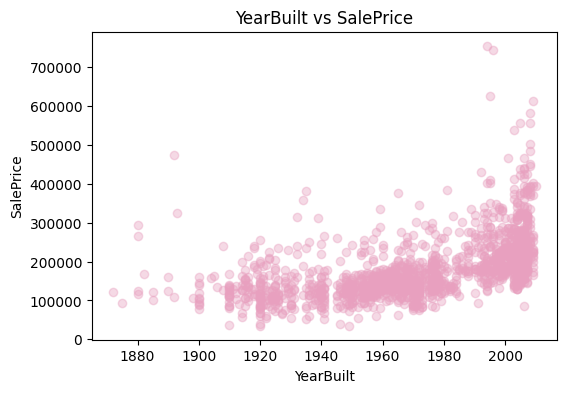

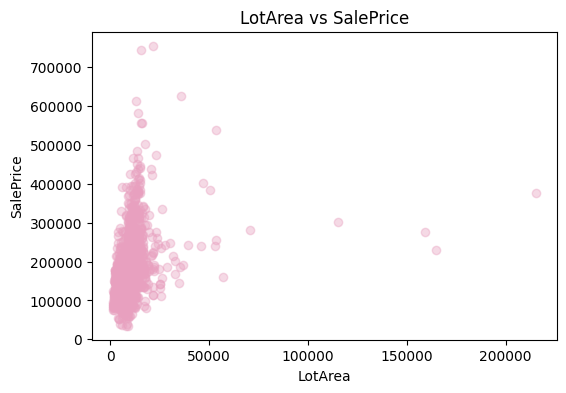

In [ ]:
for col in selected_numeric:
    if col != 'SalePrice':
        plt.figure(figsize=(6, 4))
        plt.scatter(train_raw[col], train_raw['SalePrice'], alpha=0.4, color=PINK)
        plt.xlabel(col)
        plt.ylabel('SalePrice')
        plt.title(f'{col} vs SalePrice')
        plt.savefig(
        figures_dir / "scatterplots2.png",
        dpi=300,
        bbox_inches="tight",
        )
        plt.show()

Boxplots of `SalePrice` for each selected categorical feature, to see which categories separate prices well.

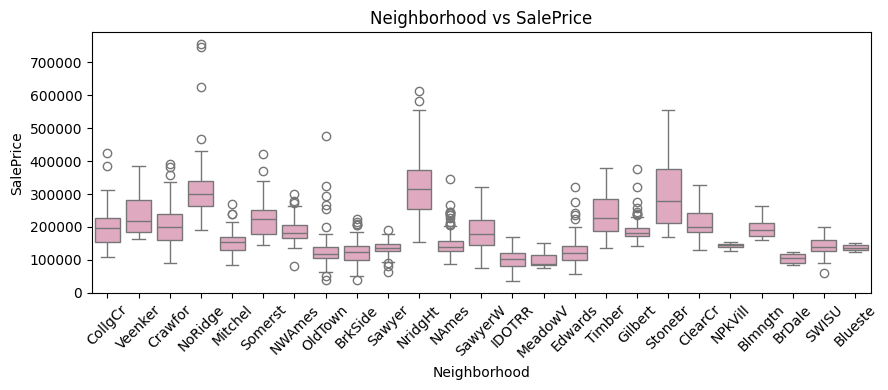

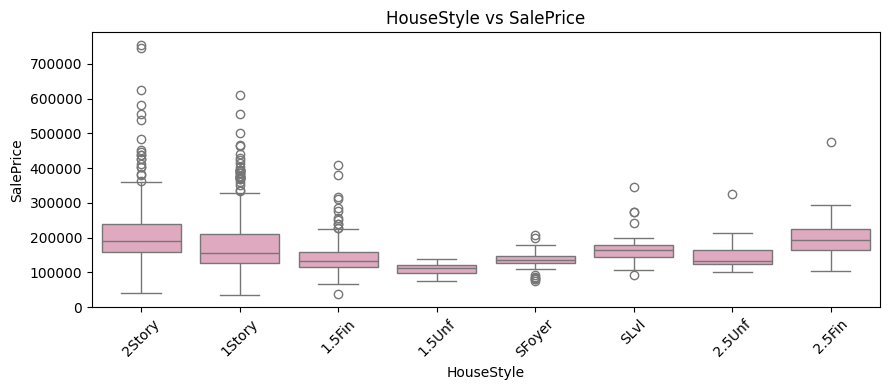

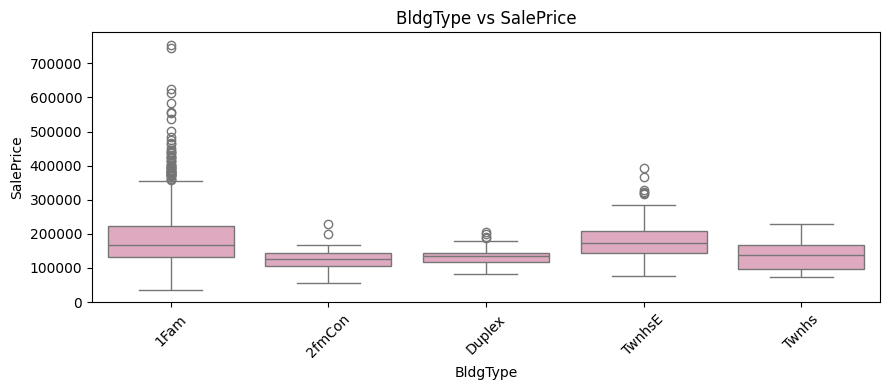

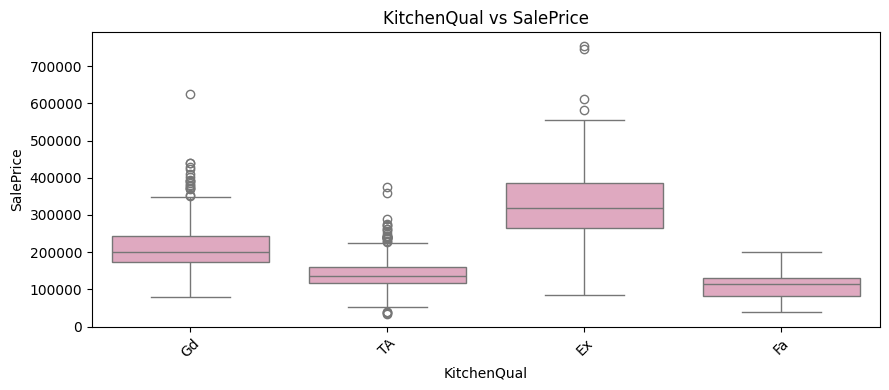

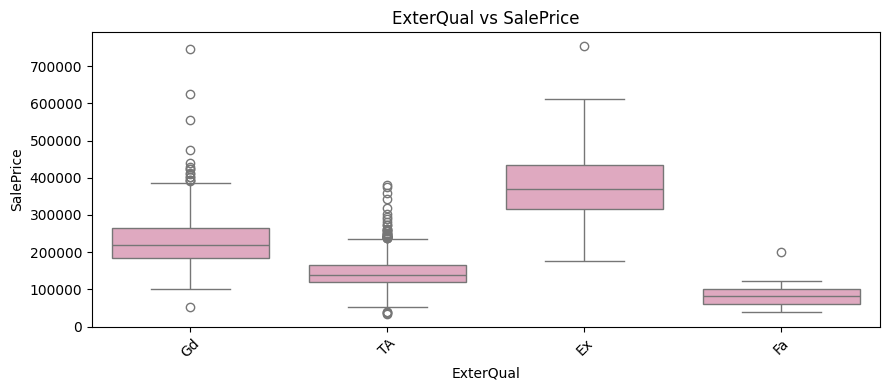

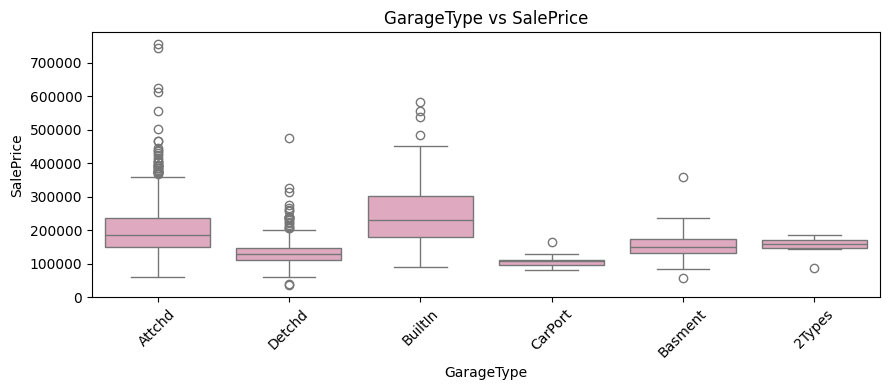

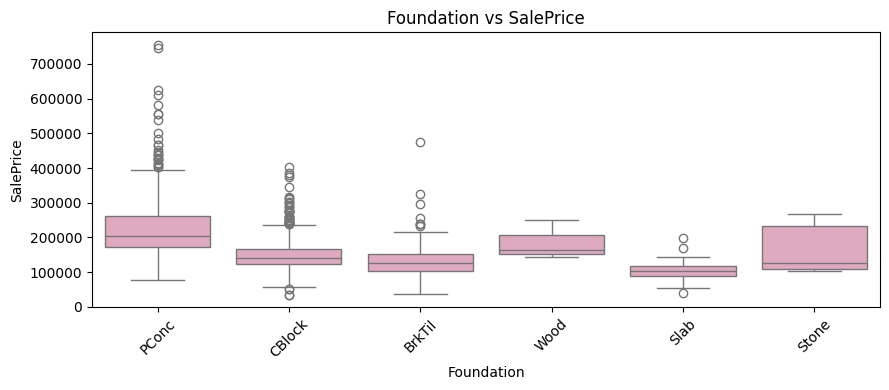

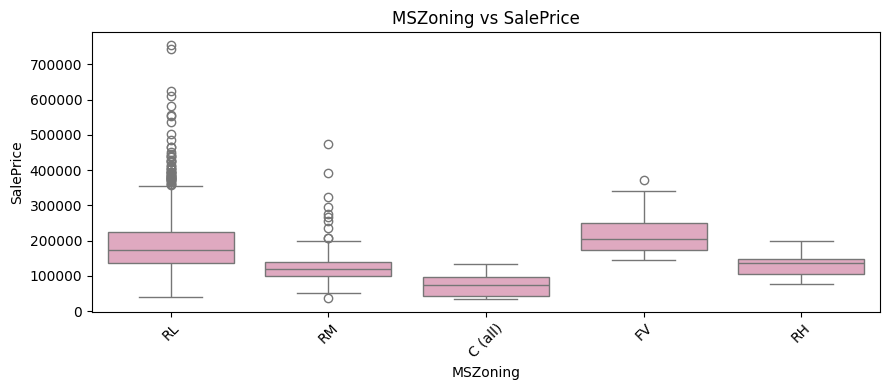

In [ ]:
for col in selected_categorical:
    plt.figure(figsize=(9, 4))
    sns.boxplot(data=train_raw, x=col, y='SalePrice', color=PINK)
    plt.xticks(rotation=45)
    plt.title(f'{col} vs SalePrice')
    plt.tight_layout()
    plt.savefig(
    figures_dir / "boxplots.png",
    dpi=300,
    bbox_inches="tight",
    )
    plt.show()

Correlation heatmap of the selected numerical features.

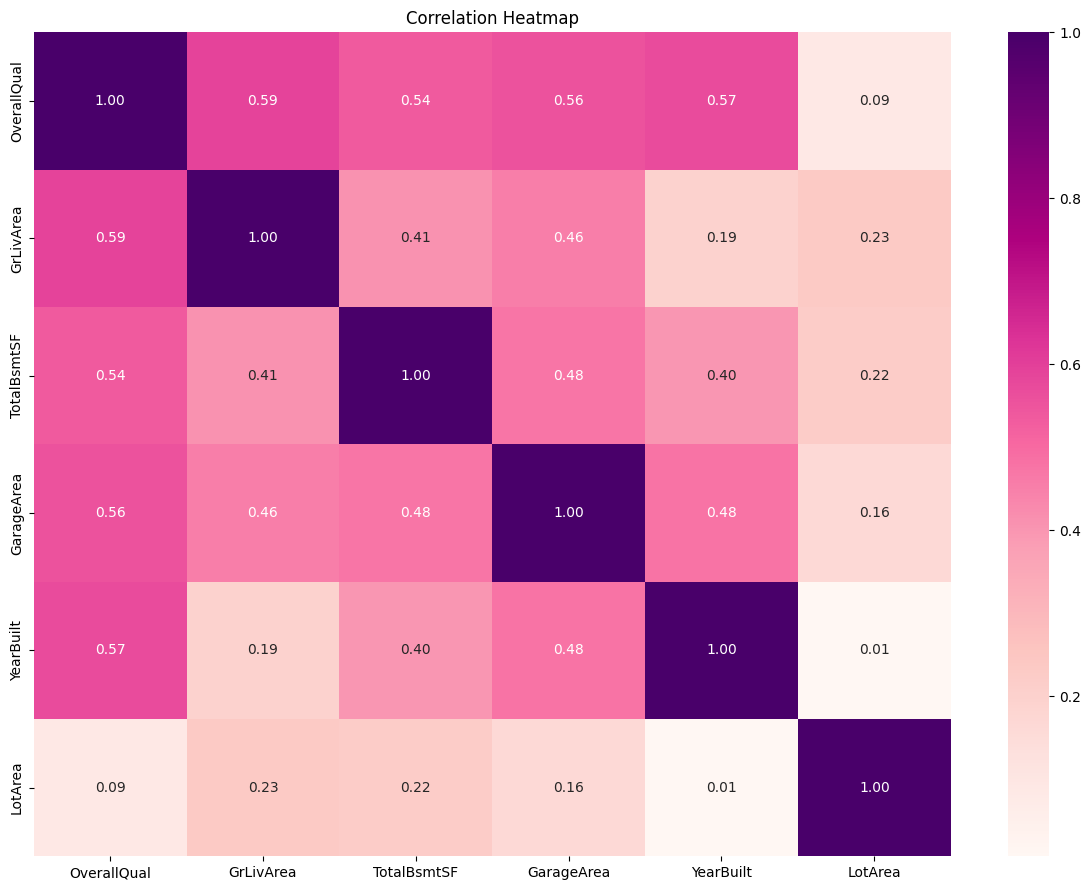

In [ ]:
plt.figure(figsize=(12, 9))

corr = train_raw[selected_numeric].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='RdPu',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig(
    figures_dir / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

The most correlated pairs among **all** numerical columns, to spot redundant features. This led to two ideas:

- **Possible columns to remove later:** `GarageArea` and `GarageYrBlt` (strongly correlated with `GarageCars` and `YearBuilt`). Nothing is removed for now.
- **New columns to add:** total bathrooms (full and half, basement included) and the bedroom ratio `BedroomAbvGr / TotRmsAbvGrd`. These are built in section 4.

In [ ]:
corr = train_raw.select_dtypes(include='number').corr()

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

corr_pairs = upper.stack().sort_values(ascending=False)

print(corr_pairs.head(15))

# cols to remove (?) - GarageArea, GarageYrBlt (not removed for now)
# new cols to add - TotFullBaths - FullBath + BsmtFullBath, TotHalfBaths - BsmtHalfBath + HalfBath, BedRoomRat - Bedroom/TotRmsAbvGrd

GarageCars    GarageArea      0.887304
GrLivArea     TotRmsAbvGrd    0.829498
YearBuilt     GarageYrBlt     0.825317
TotalBsmtSF   1stFlrSF        0.803830
OverallQual   SalePrice       0.795774
GrLivArea     SalePrice       0.734968
2ndFlrSF      GrLivArea       0.694678
BedroomAbvGr  TotRmsAbvGrd    0.680390
BsmtFinSF1    BsmtFullBath    0.658507
TotalBsmtSF   SalePrice       0.651153
YearRemodAdd  GarageYrBlt     0.641604
GarageCars    SalePrice       0.641047
GrLivArea     FullBath        0.638378
1stFlrSF      SalePrice       0.631530
GarageArea    SalePrice       0.629217
dtype: float64


## 4. Missing values and new features

`NA` means two different things in this dataset.

**`NA` is a real category** (the house doesn't have the feature) or
**`NA` is a genuinely missing value:** `LotFrontage` (filled with a median), `MasVnrArea`, `Electrical`, and `MasVnrType`, where `None` is a real category ("no veneer") and only `NA` is missing.

Instead of filling whole columns, each `NA` is checked row by row. It only counts as a category if a related numeric column agrees the feature is absent, for example no basement means `TotalBsmtSF == 0`. This is the `structural_na_cols` dictionary: the value is the numeric column to check, or `None` when there is no such column.

In [ ]:
# structural column -> numeric column that must be 0 if the feature really is absent

structural_na_cols = {
    'Alley': None, 'Fence': None, 'MiscFeature': None,
    'PoolQC': 'PoolArea', 'FireplaceQu': 'Fireplaces',
    'BsmtQual': 'TotalBsmtSF', 'BsmtCond': 'TotalBsmtSF', 'BsmtExposure': 'TotalBsmtSF',
    'BsmtFinType1': 'TotalBsmtSF', 'BsmtFinType2': 'TotalBsmtSF',
    'GarageType': 'GarageArea', 'GarageFinish': 'GarageArea',
    'GarageQual': 'GarageArea', 'GarageCond': 'GarageArea',
}

### New features

Built from the correlation analysis above and mostly personal reasoning: total full and half bathrooms (basement included), a combined bathroom count, total square footage, total porch/deck area, and the remodel age.

This is a function because it runs on train and test, and it is called at the **end** of `clean()`, after the missing values are filled. That way the sums are built from filled values and a NaN can't spread into the new columns. It is plain row-wise arithmetic, so it learns nothing from the data and can't leak.

In [ ]:
def add_features(df):
    df = df.copy()
    df['TotFullBaths'] = df['FullBath'] + df['BsmtFullBath']
    df['TotHalfBaths'] = df['HalfBath'] + df['BsmtHalfBath']
    df['TotalBathrooms'] = df['TotFullBaths'] + 0.5 * df['TotHalfBaths']
    # df['BedRoomRat'] = df['BedroomAbvGr'] / df['TotRmsAbvGrd']

    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    df['TotalPorchSF'] = (df['OpenPorchSF'] + df['EnclosedPorch'] + df['3SsnPorch'] +
                          df['ScreenPorch'] + df['WoodDeckSF'])
    df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']
    # df['QualSF'] = df['OverallQual'] * df['TotalSF']

    return df

### The cleaning function

`clean(df, stats)` runs the same steps on train and test. On train, `stats=None`, so it **learns** the medians and modes. On test, the train `stats` are passed in and only **applied**, so nothing leaks from test.

1. `MSSubClass` becomes a string, because it is a building-type code and not a quantity.
2. Structural `NA`s are kept as the `'NA'` category only when the related numeric column confirms the feature is absent. Otherwise they stay NaN, meaning really missing.
3. `MasVnrType` gets `'None'` when the veneer area is known, and `MasVnrArea` NaN becomes 0.
4. `HasGarage` is added, `GarageYrBlt` falls back to `YearBuilt` (and is capped at the sale year to fix a typo in test), and `LotFrontage_missing` flags imputed lot frontages.
5. `LotFrontage` is filled with the median of its neighborhood.
6. Remaining numeric NaNs get the train median. Remaining categorical NaNs get the train mode.
7. `add_features` runs last.

In [ ]:
def mode_ignoring_na(s):
    # most frequent real category; the 'NA' label ("feature absent") is not a candidate
    m = s[s != 'NA'].mode()
    return m.iloc[0] if len(m) else 'NA'


def clean(df, stats=None):
    df = df.copy()

    # building-type code, not a quantity
    df['MSSubClass'] = df['MSSubClass'].astype(str)

    # structural NAs (row-level check, same as before)
    for col, related in structural_na_cols.items():
        if related is None:
            df[col] = df[col].fillna('NA')
        else:
            df.loc[df[col].isna() & df[related].eq(0), col] = 'NA'

    df.loc[df['MasVnrType'].isna() & df['MasVnrArea'].eq(0), 'MasVnrType'] = 'None'
    df['MasVnrArea'] = df['MasVnrArea'].fillna(0)
    df['HasGarage'] = (df['GarageArea'].fillna(0) > 0).astype(int)
    df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])
    df['GarageYrBlt'] = df['GarageYrBlt'].clip(upper=df['YrSold'])
    df['LotFrontage_missing'] = df['LotFrontage'].isna().astype(int)

    if stats is None:  # fit mode: learn from this dataframe only
        stats = {
            'lot_by_hood': df.groupby('Neighborhood')['LotFrontage'].median(),
            'num_median': df.select_dtypes('number').median(),
            'cat_mode': df.select_dtypes(exclude='number').apply(mode_ignoring_na),
        }
        veneer_types = df.loc[
            df['MasVnrArea'].gt(0)
            & ~df['MasVnrType'].isin(['None', 'NA']),
            'MasVnrType'
        ].mode()

        stats['veneer_mode'] = (
            veneer_types.iloc[0] if len(veneer_types) else 'Unknown'
        )

    df.loc[df['MasVnrType'].isna() & df['MasVnrArea'].gt(0),'MasVnrType'] = stats['veneer_mode']

    df['LotFrontage'] = df['LotFrontage'].fillna(df['Neighborhood'].map(stats['lot_by_hood']))
    df = df.fillna(stats['num_median'])   # remaining numeric NaNs
    df = df.fillna(stats['cat_mode'])     # remaining categorical NaNs

    return add_features(df), stats

### Apply the cleaning

Train is cleaned first and returns `stats`. Test reuses those exact statistics.

In [ ]:
#apply cleaning
train, stats = clean(train_raw)
test, _ = clean(test_raw, stats)

### Do the new features help?

Correlation of each new feature with `SalePrice`, on the cleaned train data. A higher value means the feature carries more signal.

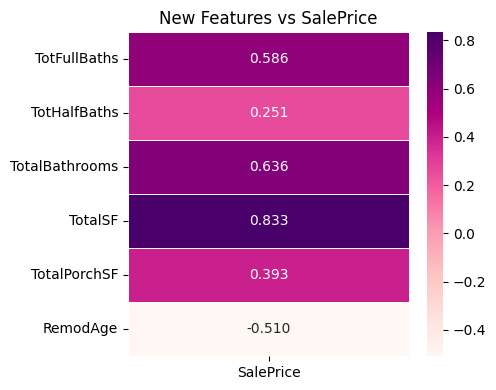

In [ ]:
#see if our new features ary any good

new_features = [
    'TotFullBaths',
    'TotHalfBaths',
    'TotalBathrooms',
    'TotalSF',
    'TotalPorchSF',
    'RemodAge',
]

corr = train[new_features + ['SalePrice']].corr()

plt.figure(figsize=(5, 4))

sns.heatmap(
    corr[['SalePrice']].drop('SalePrice'),
    annot=True,
    cmap='RdPu',
    fmt='.3f',
    linewidths=0.5

)

plt.title('New Features vs SalePrice')
plt.tight_layout()
plt.show()

## 5. Encoding

Categorical columns are split into two groups.

- **Nominal** (no natural order): one-hot encoded. `MSSubClass` is in this list now, since it is a category.
- **Ordinal** (a natural order, such as quality ratings): encoded as numbers in that order.

Every text column belongs to exactly one of the two lists.

In [ ]:
nominal_cols = ['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LandContour', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle',
                'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'CentralAir',
                'Electrical', 'GarageType', 'GarageFinish', 'PavedDrive', 'MiscFeature', 'SaleType', 'SaleCondition', 'LotConfig']
ordinal_cols = ['LotShape', 'Utilities', 'LandSlope', 'ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
                'HeatingQC', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageCond', 'PoolQC', 'Fence', 'GarageQual']

### Encoders

For the ordinal columns we spell out the category order, lowest to highest. `'NA'` ("feature absent") always comes first, so it is encoded as the lowest value. The list is matched to `ordinal_cols` by position, so the order has to be the same.

Both encoders are **fitted on train only** and then applied to train and test. Categories unseen in train are ignored (one-hot) or encoded as -1 (ordinal), and the checks at the end make sure no -1 appears.

In [ ]:
#same for ordinal data
ordinal_categories = [
    ['IR3', 'IR2', 'IR1', 'Reg'],                 # LotShape
    ['ELO', 'NoSeWa', 'NoSewr', 'AllPub'],         # Utilities
    ['Sev', 'Mod', 'Gtl'],                         # LandSlope
    ['Po', 'Fa', 'TA', 'Gd', 'Ex'],                # ExterQual
    ['Po', 'Fa', 'TA', 'Gd', 'Ex'],                # ExterCond
    ['NA', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],          # BsmtQual
    ['NA', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],          # BsmtCond
    ['NA', 'No', 'Mn', 'Av', 'Gd'],                # BsmtExposure
    ['NA', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'], # BsmtFinType1
    ['NA', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'], # BsmtFinType2
    ['Po', 'Fa', 'TA', 'Gd', 'Ex'],                # HeatingQC
    ['Po', 'Fa', 'TA', 'Gd', 'Ex'],                # KitchenQual
    ['Sal', 'Sev', 'Maj2', 'Maj1', 'Mod', 'Min2', 'Min1', 'Typ'], # Functional
    ['NA', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],          # FireplaceQu
    ['NA', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],          # GarageCond
    ['NA', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],          # PoolQC
    ['NA', 'MnWw', 'GdWo', 'MnPrv', 'GdPrv'],      # Fence
    ['NA', 'Po', 'Fa', 'TA', 'Gd', 'Ex']           # GarageQual
]

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(train[nominal_cols])
ordinal_encoder = OrdinalEncoder(categories=ordinal_categories,
                                 handle_unknown='use_encoded_value',
                                 unknown_value=-1).fit(train[ordinal_cols])

def encode(df):
    df = df.copy()
    df[ordinal_cols] = ordinal_encoder.transform(df[ordinal_cols])
    ohe = pd.DataFrame(encoder.transform(df[nominal_cols]),
                       columns=encoder.get_feature_names_out(nominal_cols),
                       index=df.index)
    return pd.concat([df.drop(columns=nominal_cols), ohe], axis=1)

train_enc = encode(train)
test_enc = encode(test)

## 6. Target, features and checks

- `y` is the **log** of `SalePrice`, so we will apply `np.exp` to the predictions before writing the submission.
- `X` is everything except `SalePrice` and `Id`.
- `X_test` is selected with `X`'s columns, so both have the same columns in the same order (it raises a `KeyError` if they differ).

No feature columns are removed at this stage.

In [ ]:
y = np.log(train_enc['SalePrice'])
X = train_enc.drop(columns=['SalePrice', 'Id'])
X_test = test_enc[X.columns]

### Sanity checks

Everything should be numeric with no NaNs, no unknown ordinal values (-1), the right number of rows (two outliers removed from train, test untouched), and the removed Ids should be gone.

In [ ]:
#check to see if cleaning went ok
print(X.shape, X_test.shape)                            # same number of columns
print(X.isna().sum().sum(), X_test.isna().sum().sum())  # 0 0
print((X_test[ordinal_cols] == -1).sum().sum())         # 0
print(X.select_dtypes(exclude='number').columns.tolist())   # []

print(X.shape[0], y.shape[0])      # expect 1458 & 1458
print(X_test.shape[0])             # expect 1459, test is unchanged!!!!
print(524 in train['Id'].values, 1299 in train['Id'].values)   # expect False False

(1458, 251) (1459, 251)
0 0
0
[]
1458 1458
1459
False False


At last, we get our clean csv files for train and test:
Running this cell will automatically download the processed csv files, so if it's unnecessary, just don't run this, the entire system is engineered for my personal comfort only

In [ ]:
train_processed = X.copy()
train_processed.insert(0, 'Id', train_enc['Id'].values)
train_processed['SalePrice_log'] = y.values

test_processed = X_test.copy()
test_processed.insert(0, 'Id', test_ids.values)

train_processed.to_csv('train_processed.csv', index=False)
test_processed.to_csv('test_processed.csv', index=False)

print(train_processed.shape, test_processed.shape)

(1458, 253) (1459, 252)


## 7. Reusable preprocessing for cross-validation

The cell below adds `make_model_pipeline(model)` for **02_Models.ipynb**. It is self-contained and tagged `house-prices-pipeline`, so the models notebook can load only this cell from **01_EDA.ipynb**, without executing the EDA, plots, outlier removal, or CSV exports. No extra Python module is needed. The cleaning functions, feature formulas, and category lists here are copied from the original cells above; if those rules change later, update their copies here too.

Give the pipeline raw feature rows and **`y = np.log(SalePrice)`**. During each fit, it first applies the existing outlier rule (`GrLivArea > 4000` and `SalePrice < 300000`) to training rows only. The cleaner then learns neighborhood medians, numeric medians, and categorical modes from the remaining training rows. The encoders fit on those cleaned training rows. Validation and test rows reuse the fitted statistics and encoders, and no validation or test rows are removed. Unknown nominal categories are ignored; unknown ordinal categories receive -1, using the original encoder settings.



In [ ]:
# This cell is self-contained: 02_Models can load it without running the EDA.
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# Structural column -> numeric column that confirms absence when it is 0.
# None means no related numeric check.
structural_na_cols = {
    'Alley': None, 'Fence': None, 'MiscFeature': None,
    'PoolQC': 'PoolArea', 'FireplaceQu': 'Fireplaces',
    'BsmtQual': 'TotalBsmtSF', 'BsmtCond': 'TotalBsmtSF',
    'BsmtExposure': 'TotalBsmtSF',
    'BsmtFinType1': 'TotalBsmtSF', 'BsmtFinType2': 'TotalBsmtSF',
    'GarageType': 'GarageArea', 'GarageFinish': 'GarageArea',
    'GarageQual': 'GarageArea', 'GarageCond': 'GarageArea',
}


def add_features(df):
    df = df.copy()
    df['TotFullBaths'] = df['FullBath'] + df['BsmtFullBath']
    df['TotHalfBaths'] = df['HalfBath'] + df['BsmtHalfBath']
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    df['TotalPorchSF'] = (
        df['OpenPorchSF'] + df['EnclosedPorch'] + df['3SsnPorch']
        + df['ScreenPorch'] + df['WoodDeckSF']
    )
    df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']

    return df


def mode_ignoring_na(s):
    # The 'NA' label ("feature absent") is not a candidate
    m = s[s != 'NA'].mode()
    return m.iloc[0] if len(m) else 'NA'


def clean(df, stats=None):
    df = df.copy()

    # building-type code ------ not a quantity
    df['MSSubClass'] = df['MSSubClass'].astype(str)

    # structural NAs
    for col, related in structural_na_cols.items():
        if related is None:
            df[col] = df[col].fillna('NA')
        else:
            df.loc[df[col].isna() & df[related].eq(0), col] = 'NA'

    # no veneer only when the recorded area is 0
    df.loc[
        df['MasVnrType'].isna() & df['MasVnrArea'].eq(0),
        'MasVnrType'
    ] = 'None'

    df['MasVnrArea'] = df['MasVnrArea'].fillna(0)

    df['HasGarage'] = (df['GarageArea'].fillna(0) > 0).astype(int)
    df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])
    df['GarageYrBlt'] = df['GarageYrBlt'].clip(upper=df['YrSold'])
    df['LotFrontage_missing'] = df['LotFrontage'].isna().astype(int)

    if stats is None:
        stats = {
            'lot_by_hood': df.groupby('Neighborhood')['LotFrontage'].median(),
            'num_median': df.select_dtypes('number').median(),
            'cat_mode': df.select_dtypes(
                exclude='number'
            ).apply(mode_ignoring_na),
        }

        # learn an actual veneer type from training rows only
        veneer_types = df.loc[
            df['MasVnrArea'].gt(0)
            & ~df['MasVnrType'].isin(['None', 'NA']),
            'MasVnrType'
        ].mode()

        stats['veneer_mode'] = (
            veneer_types.iloc[0] if len(veneer_types) else 'Unknown'
        )

    # positive area means veneer exists, even when its type is missing
    df.loc[
        df['MasVnrType'].isna() & df['MasVnrArea'].gt(0),
        'MasVnrType'
    ] = stats['veneer_mode']

    df['LotFrontage'] = df['LotFrontage'].fillna(
        df['Neighborhood'].map(stats['lot_by_hood'])
    )
    df = df.fillna(stats['num_median'])
    df = df.fillna(stats['cat_mode'])

    return add_features(df), stats


nominal_cols = [
    'MSSubClass', 'MSZoning', 'Street', 'Alley', 'LandContour',
    'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle',
    'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
    'Foundation', 'Heating', 'CentralAir', 'Electrical', 'GarageType',
    'GarageFinish', 'PavedDrive', 'MiscFeature', 'SaleType',
    'SaleCondition', 'LotConfig'
]

ordinal_cols = [
    'LotShape', 'Utilities', 'LandSlope', 'ExterQual', 'ExterCond',
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
    'HeatingQC', 'KitchenQual', 'Functional', 'FireplaceQu',
    'GarageCond', 'PoolQC', 'Fence', 'GarageQual'
]

ordinal_categories = [
    ['IR3', 'IR2', 'IR1', 'Reg'],                      # LotShape
    ['ELO', 'NoSeWa', 'NoSewr', 'AllPub'],              # Utilities
    ['Sev', 'Mod', 'Gtl'],                            # LandSlope
    ['Po', 'Fa', 'TA', 'Gd', 'Ex'],                    # ExterQual
    ['Po', 'Fa', 'TA', 'Gd', 'Ex'],                    # ExterCond
    ['NA', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],              # BsmtQual
    ['NA', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],              # BsmtCond
    ['NA', 'No', 'Mn', 'Av', 'Gd'],                    # BsmtExposure
    ['NA', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],  # BsmtFinType1
    ['NA', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],  # BsmtFinType2
    ['Po', 'Fa', 'TA', 'Gd', 'Ex'],                    # HeatingQC
    ['Po', 'Fa', 'TA', 'Gd', 'Ex'],                    # KitchenQual
    ['Sal', 'Sev', 'Maj2', 'Maj1', 'Mod', 'Min2', 'Min1', 'Typ'],
    ['NA', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],              # FireplaceQu
    ['NA', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],              # GarageCond
    ['NA', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],              # PoolQC
    ['NA', 'MnWw', 'GdWo', 'MnPrv', 'GdPrv'],          # Fence
    ['NA', 'Po', 'Fa', 'TA', 'Gd', 'Ex']               # GarageQual
]


class HousePriceCleaner(TransformerMixin, BaseEstimator):
    """Learn cleaning statistics in fit; reuse them unchanged in transform."""

    def fit(self, X, y=None):
        features = X.drop(columns=['Id', 'SalePrice'], errors='ignore')
        _, self.stats_ = clean(features)
        return self

    def transform(self, X):
        features = X.drop(columns=['Id', 'SalePrice'], errors='ignore')
        cleaned, _ = clean(features, self.stats_)
        return cleaned


class HousePricePipeline(Pipeline):
    """Remove training outliers during fit using log(SalePrice).

    Validation and test rows are retained during prediction.
    Always pass y = np.log(SalePrice).
    """

    def fit(self, X, y=None, **fit_params):
        if y is None:
            raise ValueError(
                'Pass y = np.log(SalePrice) when fitting this pipeline.'
            )

        y_log = np.asarray(y)

        if y_log.ndim != 1 or len(y_log) != len(X):
            raise ValueError(
                'X and the one-dimensional log target must have matching lengths.'
            )

        remove = (
            (X['GrLivArea'].to_numpy() > 4000)
            & (y_log < np.log(300000))
        )
        keep = ~remove
        self.removed_training_rows_ = int(remove.sum())

        if fit_params:
            raise ValueError(
                'This pipeline currently supports fit(X, y) '
                'without extra fit parameters.'
            )

        return super().fit(
            X.iloc[np.flatnonzero(keep)],
            y_log[keep]
        )


def make_model_pipeline(model):
    """Build an unfitted raw-data pipeline for a scikit-learn regressor."""
    encoding = ColumnTransformer(
        transformers=[
            (
                'nominal',
                OneHotEncoder(
                    handle_unknown='ignore',
                    sparse_output=False
                ),
                nominal_cols
            ),
            (
                'ordinal',
                OrdinalEncoder(
                    categories=ordinal_categories,
                    handle_unknown='use_encoded_value',
                    unknown_value=-1
                ),
                ordinal_cols
            ),
        ],
        remainder='passthrough',
        sparse_threshold=0,
    )

    return HousePricePipeline([
        ('clean', HousePriceCleaner()),
        ('encode', encoding),
        ('model', model),
    ])